# 06 · Periodograms of a time series: GLS and PDC

**What you'll learn**

- GLS and PDC periodograms of a scalar series (e.g. RVs), on a frequency grid in 1/day
- how the PDC is built: a distance matrix, its U-centring, and a cosine with the phase distances
- what a PDC p-value means, and why it is *local* (one frequency)
- the error-aware PDC, for points with very different error bars

Every step is a call to a public function on plain arrays: `sparta.pdc` and astropy's
`LombScargle`. The last cell runs the same analysis with the `PeriodicityDetector` object and
checks that the numbers agree. Periodograms of the spectra themselves come next: USuRPER (07)
and the partial periodograms (08).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle

from sparta.pdc import (error_aware_distance_matrix, inner_prod, pdc_power, pdc_power_level,
                        pdc_pvalue, phase_distance_matrix, scalar_distance_matrix,
                        unbiased_u_centering)
from sparta.plotting import EXTRA_COLOR, GREY, apply_style, plot_curve

apply_style()

def peak(freqs, power):
    """(period in days, power) of the highest peak of a periodogram on freqs (1/day)."""
    k = np.argmax(power)
    return 1 / freqs[k], power[k]

## 1. A scalar series: GLS and PDC

40 measurements at random times over 100 days of a sinusoid with a 7.3-day period, plus noise:
two plain arrays, times in days and values.

In [2]:
# Simulate 40 noisy observations of a 7.3-day sinusoid at random times (days)
rng = np.random.default_rng(42)
t = np.sort(rng.uniform(0, 100, 40))                   # days
P_true = 7.3
y = np.sin(2 * np.pi * t / P_true) + 0.5 * rng.standard_normal(t.size)
n = t.size

**The frequency grid.** Frequencies are in 1/day. A peak is about $1/T$ wide ($T$ = 100 days,
the time span), so the grid step must be several times finer than 0.01/day: here 0.0005/day.
The grid starts above 0, where the phase $\Delta t \bmod 1/f$ is undefined.

**GLS** is astropy's `LombScargle` with its defaults: a sinusoid fitted at every trial frequency
([periodograms § GLS](../../docs/periodograms.md#gls)).

In [3]:
# Frequency grid (1/day): step much finer than the peak width 1/T
freqs = np.arange(0.01, 1.0, 1 / 2000)                 # 1/day, the end excluded
print(f"{freqs.size} frequencies from {freqs[0]} to {freqs[-1]:.4f} 1/day")

# GLS with astropy's LombScargle, and its highest peak
gls = LombScargle(t, y).power(freqs)
print(f"GLS: highest peak at P = {peak(freqs, gls)[0]:.3f} days (power {peak(freqs, gls)[1]:.3f})")

1980 frequencies from 0.01 to 0.9995 1/day
GLS: highest peak at P = 7.273 days (power 0.833)


**PDC** (Zucker 2018) asks a more general question: are pairs of points that are close in
*phase* also close in *value*? It is a distance correlation, so it works for any periodic shape.
Three steps:

1. the values' distances, $a_{ij} = |y_i - y_j|$ (`scalar_distance_matrix`);
2. U-centring, once (`unbiased_u_centering`), which makes the statistic about 0 for unrelated
   data. Its factors are singular for $n \le 3$, which raises;
3. at each trial frequency $f = 1/P$, the phase distances $b_{ij} = \varphi_{ij}(P - \varphi_{ij})$,
   $\varphi_{ij} = (t_i - t_j) \bmod P$ (`phase_distance_matrix`), U-centred the same way; the
   power is the cosine of the two centred matrices. `pdc_power` scans the grid.

The centring factors, the biased variant and the result keys are in
[periodograms § PDC](../../docs/periodograms.md#pdc-phase-distance-correlation-zucker-2018).

In [4]:
# PDC: distances between the values, U-centred once
a = scalar_distance_matrix(y)                          # (n, n), |y_i - y_j|
A = unbiased_u_centering(a, n)
# The power at every frequency of the grid (pdc_power)
pdc = pdc_power(t, freqs, A)                           # the unbiased PDC on the whole grid

# Step 3 by hand at the true period: the cosine under the U-centred inner product
# Check the third step by hand at the true period: the cosine of the two U-centred matrices
B = unbiased_u_centering(phase_distance_matrix(t, 1 / P_true), n)
by_hand = inner_prod(A, B) / np.sqrt(inner_prod(A, A) * inner_prod(B, B))
scan = pdc_power(t, [1 / P_true], A)[0]
# The hand-made value must equal pdc_power's
print(f"PDC at P = {P_true} d: by hand {by_hand:.6f}, pdc_power {scan:.6f}")
# Verify they agree
assert np.isclose(by_hand, scan, rtol=1e-12, atol=0)

# The strongest peak of the scan
print(f"PDC: highest peak at P = {peak(freqs, pdc)[0]:.3f} days (power {peak(freqs, pdc)[1]:.3f})")
# With three epochs the centring is singular, so it must raise
try:
    unbiased_u_centering(a[:3, :3], 3)
except ValueError as err:
    print(f"three epochs: ValueError: {err}")

PDC at P = 7.3 d: by hand 0.640201, pdc_power 0.640201
PDC: highest peak at P = 7.326 days (power 0.643)
three epochs: ValueError: The unbiased (U-centered) PDC needs at least 4 epochs; got n = 3. Its 1/(n(n-3)) and /(n-2) factors are singular or negative for n <= 3.


**p-values.** `pdc_pvalue(power, n)` is the probability of a peak this high *at one given
frequency* if there were no signal (Shen et al. 2019); `pdc_power_level(p, n)` is the power a
p-value needs. Searching many frequencies gives noise many chances: a rough look-elsewhere
factor is the number of independent frequencies, about $T (f_{\max} - f_{\min})$. The
approximation and its limits: [periodograms § p-values](../../docs/periodograms.md#p-values).

In [5]:
# Local p-value of the peak, the number of independent frequencies, and the power level for p = 1e-3
p_local = pdc_pvalue(peak(freqs, pdc)[1], n)
n_indep = np.ptp(t) * (freqs[-1] - freqs[0])
level = pdc_power_level(1e-3, n)

# A rough global p-value: the local one times the number of independent frequencies
print(f"local p-value of the PDC peak: {p_local:.1e}")
print(f"~{n_indep:.0f} independent frequencies -> global p-value roughly {min(1, p_local * n_indep):.1e}")
print(f"PDC power for a local p-value of 1e-3: {level:.3f}")
# The power level and the p-value must be inverse to each other
assert np.isclose(pdc_pvalue(level, n), 1e-3)

local p-value of the PDC peak: 2.4e-07
~92 independent frequencies -> global p-value roughly 2.2e-05
PDC power for a local p-value of 1e-3: 0.246


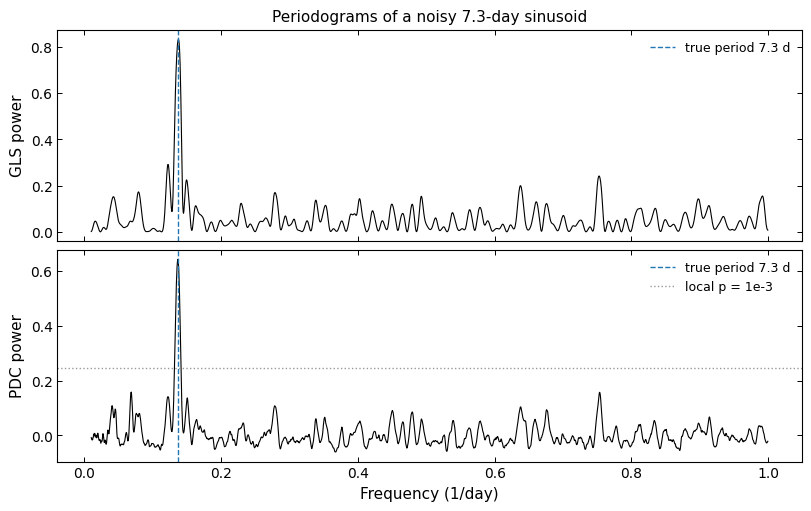

In [6]:
# Plot both periodograms with the true period and the p = 1e-3 level
fig, axs = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for ax, (name, power) in zip(axs, {"GLS": gls, "PDC": pdc}.items()):
    plot_curve(ax, freqs, power, lw=0.8)
    ax.axvline(1 / P_true, color=EXTRA_COLOR, ls="--", lw=1, label=f"true period {P_true} d")
    ax.set_ylabel(f"{name} power")
axs[1].axhline(level, color=GREY, ls=":", label="local p = 1e-3")
axs[0].set_title("Periodograms of a noisy 7.3-day sinusoid")
axs[1].set_xlabel("Frequency (1/day)")
axs[0].legend()
axs[1].legend()
plt.show()

## 2. When error bars differ: the error-aware PDC

The plain PDC treats noisy and precise points alike. The error-aware PDC (Binnenfeld, Shahaf &
Zucker 2024) replaces $|y_i - y_j|$ by a distance between two Gaussian measurements that uses
each pair's error bars (`error_aware_distance_matrix`; the formula, exactly as published, is in
[periodograms § error-aware PDC](../../docs/periodograms.md#error-aware-pdc-binnenfeld-shahaf--zucker-2024)). With
vanishing errors it tends to $(|y_i - y_j|/\sqrt2)^{1/2}$, not to $|y_i - y_j|$, so the two PDCs
differ even then:

In [7]:
# With vanishing errors the error-aware distance tends to (|Δy|/√2)^(1/2)
d_tiny = error_aware_distance_matrix([0.0, 1.0], [1e-6, 1e-6])[0, 1]
print(f"|Δy| = 1 with errors of 1e-6: d = {d_tiny:.6f}; (1/√2)^(1/2) = {2 ** -0.25:.6f}")
# Verify the limit
assert np.isclose(d_tiny, 2 ** -0.25, rtol=1e-5)

|Δy| = 1 with errors of 1e-6: d = 0.840896; (1/√2)^(1/2) = 0.840896


The rest of the PDC is unchanged: U-centre, then scan. One data set can go either way, so we
compare the two distances over 30 simulated data sets with exponentially distributed error bars,
and count how often the highest peak is the true period:

In [8]:
# Compare plain and error-aware PDC over 30 simulated data sets
freqs_30 = np.arange(0.02, 1.0, 1 / 1000)              # 1/day
# Count how often the highest peak is the true period
hits = {"plain": 0, "error-aware": 0}
for seed in range(30):
# One data set: random times and very unequal error bars
    r = np.random.default_rng(seed)
    ts = np.sort(r.uniform(0, 100, 40))
    err = r.exponential(1.0, ts.size)                  # very unequal error bars
    ys = np.sin(2 * np.pi * ts / P_true) + err * r.standard_normal(ts.size)
# The two distance matrices, each U-centred and scanned
    distances = {"plain": scalar_distance_matrix(ys),
                 "error-aware": error_aware_distance_matrix(ys, err)}
    powers = {key: pdc_power(ts, freqs_30, unbiased_u_centering(d, ts.size))
              for key, d in distances.items()}
# A hit is a highest peak within 0.01/day of the true frequency
    for key, power in powers.items():
        hits[key] += abs(freqs_30[np.argmax(power)] - 1 / P_true) < 0.01

# Report the hit counts
for key, n_hit in hits.items():
    print(f"{key:12s} PDC: true period found in {n_hit} of 30 data sets")

plain        PDC: true period found in 23 of 30 data sets
error-aware  PDC: true period found in 26 of 30 data sets


## The same numbers with the objects

`Observations` and its `PeriodicityDetector` chain the same functions
([howto/04_find_periods](../howto/04_find_periods.ipynb) is the short recipe): the grid, GLS,
PDC, the p-value levels and the error-aware PDC are identical, bit for bit.

In [9]:
# Object path: the same series through Observations and PeriodicityDetector
from sparta import Observations, TimeSeries

obs = Observations(time_series=TimeSeries(times=t, vals=list(y)))
obs.init_periodicity_detector(freq_range=(0.01, 1.0), periodogram_grid_resolution=2000)
# Compute GLS and the PDC with the detector
pd = obs.periodicity_detector
pd.calc_gls()
pd.calc_pdc()
# Verify the grid, the powers and the p-value level match the atoms, bit for bit
assert np.array_equal(pd.frequency_grid, freqs)
assert np.array_equal(pd.results_power["GLS"], gls)
assert np.array_equal(pd.results_power["PDC_unbiased"], pdc)
assert np.array_equal(pd.calc_pdc_pval([1e-3], inverse_sf=True), pdc_power_level([1e-3], n))

# The error-aware PDC on the last data set of section 2
last = Observations(time_series=TimeSeries(times=ts, vals=list(ys), errors=list(err)))
last.init_periodicity_detector(freq_range=(0.02, 1.0), periodogram_grid_resolution=1000)
last.periodicity_detector.calc_pdc(errors=True)                 # section 2, data set 29
# It must match the atoms too
assert np.array_equal(last.periodicity_detector.results_power["PDC_errors_unbiased"], powers["error-aware"])
print("GLS, PDC, p-value levels, error-aware PDC: identical")

GLS, PDC, p-value levels, error-aware PDC: identical


## Summary / next

- The frequency grid is an array in 1/day, with a step several times finer than $1/T$; GLS is
  `LombScargle(t, y).power(freqs)`.
- The PDC is three atoms: a distance matrix (`scalar_distance_matrix`), `unbiased_u_centering`
  (raises for $n \le 3$), and `pdc_power` against the phase distances.
- `pdc_pvalue` / `pdc_power_level` are local, for one frequency; correct for the number of
  frequencies searched.
- `error_aware_distance_matrix` uses the error bars; with very unequal ones it found the true
  period more often.

**Next:** [`07_usurper`](07_usurper.ipynb): the same scan on the spectra themselves, with no RVs.